# 01. Predicción de partidas de League of Legends con un MLP

**Douglas Pérez**  
**Carnet 22003865**

## 1. Introducción y objetivo

Quise medir cuánto se puede anticipar del resultado de una partida de League of Legends al minuto 10. El objetivo es predecir si gana el equipo azul a partir de estadísticas de ambos equipos hasta ese momento.

Elegí este dataset porque registra oro, experiencia y objetivos al mismo minuto en 9,879 partidas clasificatorias de rango alto. Puedo comparar dos MLP con un baseline de logistic regression usando el mismo punto de partida. [Dataset de Bobbyscience en Kaggle](https://www.kaggle.com/datasets/bobbyscience/league-of-legends-diamond-ranked-games-10-min)

## 2. Carga y análisis exploratorio (EDA)

Usé CPU y una seed fija para poder repetir el experimento en un runtime estándar de Colab.

In [1]:
import hashlib
import io
import os
import random
import zipfile
from pathlib import Path
from urllib.request import urlopen

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    log_loss,
    precision_recall_fscore_support,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEMILLA = 42
DISPOSITIVO = torch.device("cpu")
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.use_deterministic_algorithms(True)

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(f"PyTorch {torch.__version__} | scikit-learn {sklearn.__version__} | "
      f"pandas {pd.__version__} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")
print(f"Dispositivo: {DISPOSITIVO} | Seed: {SEMILLA}")

PyTorch 2.14.1+cpu | scikit-learn 1.6.1 | pandas 2.2.3 | NumPy 2.4.6 | Matplotlib 3.10.0
Dispositivo: cpu | Seed: 42


Uso la versión 1 del dataset y verifico el SHA-256 del CSV. Si falla la descarga automática, se puede subir a Colab el ZIP de Kaggle como **league-of-legends-v1.zip** o indicar la ruta mediante **LOL_DATASET_ZIP**.

In [2]:
URL_DATOS = (
    "https://www.kaggle.com/api/v1/datasets/download/bobbyscience/"
    "league-of-legends-diamond-ranked-games-10-min?datasetVersionNumber=1"
)
CSV_DATOS = "high_diamond_ranked_10min.csv"
HUELLA_CSV = "82b2e23279097c2dac616e966eb2911711c428d41b6382b4cdb15da4892f9ca6"
ruta_zip = Path(os.environ.get("LOL_DATASET_ZIP", "league-of-legends-v1.zip"))

if ruta_zip.is_file():
    archivo_zip = ruta_zip.read_bytes()
else:
    with urlopen(URL_DATOS, timeout=45) as respuesta:
        archivo_zip = respuesta.read()

if not zipfile.is_zipfile(io.BytesIO(archivo_zip)):
    raise ValueError("Kaggle no devolvió un ZIP. Descarga la versión 1 y usa la ruta indicada arriba.")

with zipfile.ZipFile(io.BytesIO(archivo_zip)) as paquete:
    contenido_csv = paquete.read(CSV_DATOS)
if hashlib.sha256(contenido_csv).hexdigest() != HUELLA_CSV:
    raise ValueError("El CSV no coincide con la versión 1 de Kaggle.")

datos = pd.read_csv(io.BytesIO(contenido_csv))
assert datos.shape == (9879, 40)
assert datos["gameId"].is_unique and set(datos["blueWins"]) == {0, 1}
assert datos.isna().sum().sum() == 0
print(f"{len(datos):,} partidas | {datos.shape[1]} columnas | 0 valores faltantes")
display(datos[["gameId", "blueWins", "blueGoldDiff", "blueKills", "redKills"]].head())

9,879 partidas | 40 columnas | 0 valores faltantes


,gameId,blueWins,blueGoldDiff,blueKills,redKills
0,4519157822,0,643,9,6
1,4523371949,0,-2908,5,5
2,4521474530,0,-1172,7,11
3,4524384067,0,-1321,4,5
4,4436033771,0,-1004,6,6


El target es **blueWins** (1 si gana el azul, 0 si gana el rojo). Las clases están balanceadas, con 4,930 victorias del azul y 4,949 del rojo. El CSV trae un registro por partida y todos los valores están presentes.

,blueGoldDiff,blueExperienceDiff,blueKills,redKills
count,9879.0,9879.0,9879.0,9879.0
mean,14.4,-33.6,6.2,6.1
std,2453.3,1920.4,3.0,2.9
min,-10830.0,-9333.0,0.0,0.0
25%,-1585.5,-1290.5,4.0,4.0
50%,14.0,-28.0,6.0,6.0
75%,1596.0,1212.0,8.0,8.0
max,11467.0,8348.0,22.0,22.0


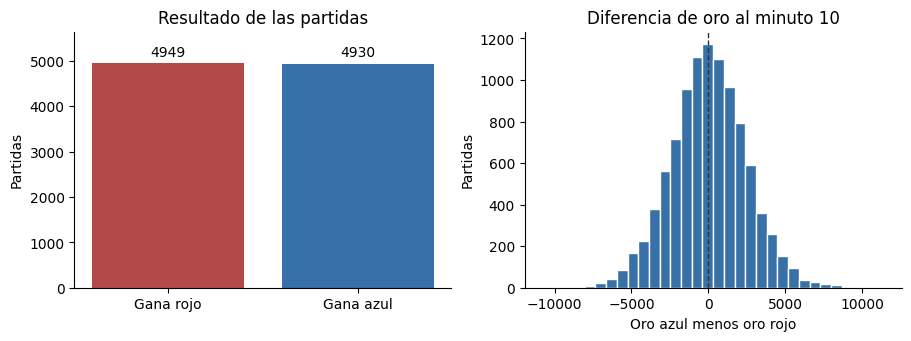

In [3]:
nombres_clases = ["Gana rojo", "Gana azul"]
resumen_clases = datos["blueWins"].value_counts().sort_index()
display(datos[["blueGoldDiff", "blueExperienceDiff", "blueKills", "redKills"]]
        .describe().round(1))

fig, ejes = plt.subplots(1, 2, figsize=(9, 3.3), layout="constrained")
barras = ejes[0].bar(nombres_clases, resumen_clases.values, color=["#b44949", "#3771a8"])
ejes[0].bar_label(barras, padding=3)
ejes[0].set(ylim=(0, max(resumen_clases) * 1.14), ylabel="Partidas",
            title="Resultado de las partidas")
ejes[1].hist(datos["blueGoldDiff"], bins=32, color="#3771a8", edgecolor="white")
ejes[1].axvline(0, color="#303030", linestyle="--", linewidth=1)
ejes[1].set(xlabel="Oro azul menos oro rojo", ylabel="Partidas",
            title="Diferencia de oro al minuto 10")
plt.show()

## 3. Preprocesamiento y split

Construí 12 features como diferencias entre azul y rojo y agregué un indicador de first blood. Así represento la ventaja relativa con una sola columna por estadística. Dejé fuera **gameId**, el target y las columnas que repiten una diferencia ya calculada.

Hice un split estratificado por partida de 70 % train, 15 % validation y 15 % test. Ajusté **StandardScaler** con train y apliqué esa misma transformación a validation y test para evitar data leakage.

In [4]:
diferencias = {
    "oro": "TotalGold",
    "experiencia": "TotalExperience",
    "bajas": "Kills",
    "asistencias": "Assists",
    "guardianes_colocados": "WardsPlaced",
    "guardianes_destruidos": "WardsDestroyed",
    "dragones": "Dragons",
    "heraldos": "Heralds",
    "torres": "TowersDestroyed",
    "nivel_promedio": "AvgLevel",
    "subditos_linea": "TotalMinionsKilled",
    "subditos_jungla": "TotalJungleMinionsKilled",
}
variables = pd.DataFrame({
    nombre: datos[f"blue{columna}"] - datos[f"red{columna}"]
    for nombre, columna in diferencias.items()
})
variables["primera_baja_azul"] = datos["blueFirstBlood"]
etiquetas = datos["blueWins"].to_numpy()

indices_desarrollo, indices_prueba = train_test_split(
    np.arange(len(datos)), test_size=0.15, stratify=etiquetas, random_state=SEMILLA
)
indices_entrenamiento, indices_validacion = train_test_split(
    indices_desarrollo, test_size=0.15 / 0.85,
    stratify=etiquetas[indices_desarrollo], random_state=SEMILLA,
)
indices = np.concatenate([indices_entrenamiento, indices_validacion, indices_prueba])
assert len(np.unique(indices)) == len(datos)

escalador = StandardScaler()
x_entrenamiento = escalador.fit_transform(variables.iloc[indices_entrenamiento]).astype("float32")
x_validacion = escalador.transform(variables.iloc[indices_validacion]).astype("float32")
x_prueba = escalador.transform(variables.iloc[indices_prueba]).astype("float32")
y_entrenamiento = etiquetas[indices_entrenamiento]
y_validacion = etiquetas[indices_validacion]
y_prueba = etiquetas[indices_prueba]
assert np.allclose(x_entrenamiento.mean(axis=0), 0, atol=1e-5)

resumen_particiones = pd.DataFrame(
    {
        "Partidas": [len(y) for y in (y_entrenamiento, y_validacion, y_prueba)],
        "Victorias del azul (%)": [100 * y.mean() for y in (y_entrenamiento, y_validacion, y_prueba)],
    },
    index=["Train", "Validation", "Test"],
)
display(resumen_particiones.round(2))

,Partidas,Victorias del azul (%)
Train,6915,49.91
Validation,1482,49.87
Test,1482,49.93


En train, la mediana de la diferencia de oro cambia según quién gana. Las distribuciones se traslapan, así que el oro al minuto 10 da una señal útil y deja partidas difíciles de distinguir.

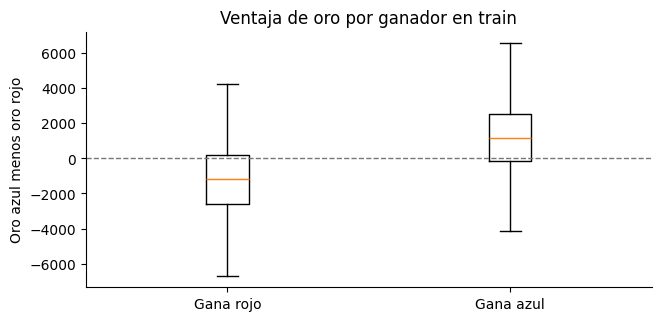

In [5]:
oro_entrenamiento = variables.iloc[indices_entrenamiento]["oro"].to_numpy()
fig, ax = plt.subplots(figsize=(6.5, 3.1), layout="constrained")
ax.boxplot([oro_entrenamiento[y_entrenamiento == clase] for clase in (0, 1)], showfliers=False)
ax.axhline(0, color="#777777", linestyle="--", linewidth=1)
ax.set(xticks=[1, 2], xticklabels=nombres_clases, ylabel="Oro azul menos oro rojo",
       title="Ventaja de oro por ganador en train")
plt.show()

## 4. Definición del modelo

Comparé un MLP de 32 unidades en una hidden layer con otro de 64 y 32 unidades y dropout de 0.20. Los dos reciben las 13 features y usan ReLU en las hidden layers. La salida es un logit que convierto con sigmoid para estimar la probabilidad de victoria azul.

Entrené el baseline de logistic regression con el mismo split y las mismas features para medir qué aportan las hidden layers.

In [6]:
configuraciones = {
    "MLP de una capa": {"ocultas": (32,), "dropout": 0.0},
    "MLP de dos capas": {"ocultas": (64, 32), "dropout": 0.20},
}


def crear_mlp(n_entradas, ocultas, dropout):
    capas = []
    n_anterior = n_entradas
    for n_neuronas in ocultas:
        capas.extend([nn.Linear(n_anterior, n_neuronas), nn.ReLU()])
        if dropout > 0:
            capas.append(nn.Dropout(dropout))
        n_anterior = n_neuronas
    capas.append(nn.Linear(n_anterior, 1))
    return nn.Sequential(*capas)


for nombre, config in configuraciones.items():
    modelo = crear_mlp(variables.shape[1], **config)
    parametros = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    print(f"{nombre} | {parametros:,} parámetros entrenables")
    print(modelo, "\n")

MLP de una capa | 481 parámetros entrenables
Sequential(
  (0): Linear(in_features=13, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=1, bias=True)
) 

MLP de dos capas | 3,009 parámetros entrenables
Sequential(
  (0): Linear(in_features=13, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=64, out_features=32, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.2, inplace=False)
  (6): Linear(in_features=32, out_features=1, bias=True)
) 



## 5. Training y selección del checkpoint

Para ambos MLP usé **BCEWithLogitsLoss** y **Adam**, con learning rate de 0.001, batch size de 256 y un máximo de 50 epochs. Apliqué early stopping con paciencia de 8 epochs y elegí el checkpoint con menor validation loss. Esta métrica toma en cuenta las probabilidades antes de aplicar el threshold.

In [7]:
LEARNING_RATE = 0.001
BATCH_SIZE = 256
MAX_EPOCHS = 50
PACIENCIA = 8
MEJORA_MINIMA = 1e-5
carpeta_checkpoints = Path(os.environ.get("LOL_CHECKPOINT_DIR", "checkpoints"))
carpeta_checkpoints.mkdir(parents=True, exist_ok=True)


def a_tensores(x, y):
    return (
        torch.as_tensor(x, dtype=torch.float32, device=DISPOSITIVO),
        torch.as_tensor(y, dtype=torch.float32, device=DISPOSITIVO),
    )


lotes_entrenamiento = TensorDataset(*a_tensores(x_entrenamiento, y_entrenamiento))
tensores_entrenamiento = a_tensores(x_entrenamiento, y_entrenamiento)
tensores_validacion = a_tensores(x_validacion, y_validacion)
criterio = nn.BCEWithLogitsLoss()


@torch.inference_mode()
def evaluar_tensores(modelo, tensores):
    modelo.eval()
    x, y = tensores
    logits = modelo(x).squeeze(-1)
    perdida = criterio(logits, y).item()
    probabilidades = torch.sigmoid(logits).cpu().numpy()
    aciertos = ((logits >= 0) == y.bool()).float().mean().item()
    return perdida, aciertos, probabilidades


def entrenar_mlp(modelo, ruta_checkpoint):
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE)
    lotes = DataLoader(
        lotes_entrenamiento, batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(SEMILLA),
    )
    historial = []
    mejor_perdida = float("inf")
    mejor_epoch = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        modelo.train()
        for x_lote, y_lote in lotes:
            optimizador.zero_grad()
            logits = modelo(x_lote).squeeze(-1)
            perdida = criterio(logits, y_lote)
            perdida.backward()
            optimizador.step()

        # Calculo train y validation en eval() para desactivar dropout en ambas curvas.
        loss_train, acc_train, _ = evaluar_tensores(modelo, tensores_entrenamiento)
        loss_val, acc_val, _ = evaluar_tensores(modelo, tensores_validacion)
        historial.append({
            "epoch": epoch, "loss_train": loss_train, "loss_val": loss_val,
            "acc_train": acc_train, "acc_val": acc_val,
        })

        if loss_val < mejor_perdida - MEJORA_MINIMA:
            mejor_perdida = loss_val
            mejor_epoch = epoch
            torch.save(modelo.state_dict(), ruta_checkpoint)
        if epoch - mejor_epoch >= PACIENCIA:
            break

    return pd.DataFrame(historial), mejor_epoch, mejor_perdida

In [8]:
referencia = LogisticRegression(max_iter=1000, random_state=SEMILLA)
referencia.fit(x_entrenamiento, y_entrenamiento)
prob_val_referencia = referencia.predict_proba(x_validacion)[:, 1]
loss_val_referencia = log_loss(y_validacion, prob_val_referencia, labels=[0, 1])

historiales = {}
resultados_validacion = []
rutas_checkpoints = {}
for numero, (nombre, config) in enumerate(configuraciones.items(), start=1):
    torch.manual_seed(SEMILLA)
    modelo = crear_mlp(variables.shape[1], **config).to(DISPOSITIVO)
    ruta = carpeta_checkpoints / f"mlp_{numero}_mejor.pt"
    historial, mejor_epoch, loss_val = entrenar_mlp(modelo, ruta)
    historiales[nombre] = historial
    rutas_checkpoints[nombre] = ruta
    resultados_validacion.append({
        "Modelo": nombre, "Epochs": len(historial),
        "Best epoch": mejor_epoch, "Validation loss": loss_val,
        "Validation accuracy": historial.loc[mejor_epoch - 1, "acc_val"],
    })

tabla_validacion = pd.DataFrame(resultados_validacion).sort_values("Validation loss")
ganador = tabla_validacion.iloc[0]
nombre_elegido = ganador["Modelo"]
modelo_elegido = crear_mlp(variables.shape[1], **configuraciones[nombre_elegido]).to(DISPOSITIVO)
modelo_elegido.load_state_dict(
    torch.load(rutas_checkpoints[nombre_elegido], map_location=DISPOSITIVO, weights_only=True)
)
display(tabla_validacion.round(4))
print(f"Logistic regression | Validation loss: {loss_val_referencia:.4f}")
print(f"Checkpoint seleccionado: {nombre_elegido}, epoch {int(ganador['Best epoch'])}")

,Modelo,Epochs,Best epoch,Validation loss,Validation accuracy
0,MLP de una capa,50,47,0.5245,0.7375
1,MLP de dos capas,31,23,0.5250,0.7422


Logistic regression | Validation loss: 0.5207
Checkpoint seleccionado: MLP de una capa, epoch 47


## 6. Evaluación y resultados

Comparé train loss con validation loss para buscar señales de overfitting. Reservé test para comparar el MLP elegido con logistic regression. Usé un threshold de 0.50 y macro averaging para dar el mismo peso a las dos clases.

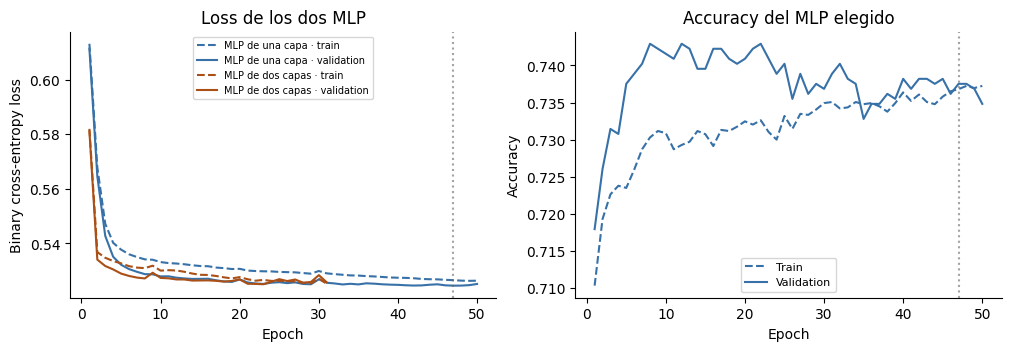

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
colores = ["#3771a8", "#aa4f15"]
for color, (nombre, historial) in zip(colores, historiales.items()):
    ejes[0].plot(historial["epoch"], historial["loss_train"], "--", color=color,
                 label=f"{nombre} · train")
    ejes[0].plot(historial["epoch"], historial["loss_val"], color=color,
                 label=f"{nombre} · validation")
ejes[0].axvline(ganador["Best epoch"], color="#666666", alpha=0.6, linestyle=":")
ejes[0].set(xlabel="Epoch", ylabel="Binary cross-entropy loss", title="Loss de los dos MLP")
ejes[0].legend(fontsize=7)

historial_elegido = historiales[nombre_elegido]
ejes[1].plot(historial_elegido["epoch"], historial_elegido["acc_train"],
             "--", color=colores[0], label="Train")
ejes[1].plot(historial_elegido["epoch"], historial_elegido["acc_val"],
             color=colores[0], label="Validation")
ejes[1].axvline(ganador["Best epoch"], color="#666666", alpha=0.6, linestyle=":")
ejes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy del MLP elegido")
ejes[1].legend(fontsize=8)
plt.show()

,Loss,Accuracy,Macro precision,Macro recall,Macro F1-score,ROC-AUC
MLP de una capa,0.5350,0.7126,0.7128,0.7126,0.7125,0.8028
Logistic regression,0.5288,0.7193,0.7194,0.7193,0.7193,0.8072


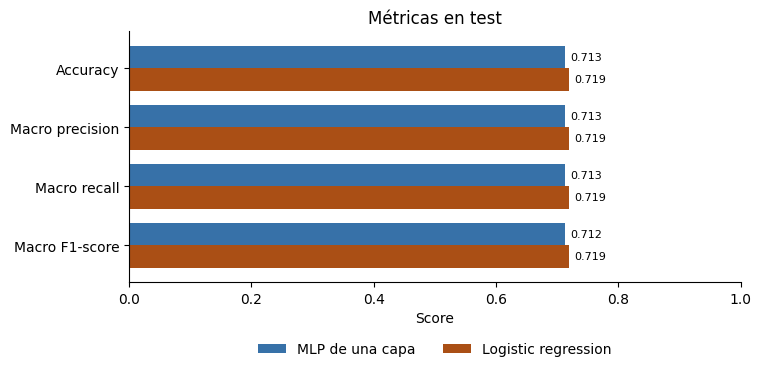

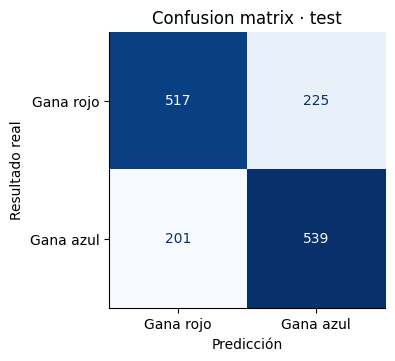

In [10]:
loss_prueba_mlp, _, prob_prueba_mlp = evaluar_tensores(
    modelo_elegido, a_tensores(x_prueba, y_prueba)
)
prob_prueba_referencia = referencia.predict_proba(x_prueba)[:, 1]
pred_prueba_mlp = (prob_prueba_mlp >= 0.50).astype(int)
pred_prueba_referencia = (prob_prueba_referencia >= 0.50).astype(int)


def resumir_metricas(y_real, y_predicha, probabilidades, perdida):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_real, y_predicha, average="macro", zero_division=0
    )
    return {
        "Loss": perdida,
        "Accuracy": accuracy_score(y_real, y_predicha),
        "Macro precision": precision,
        "Macro recall": recall,
        "Macro F1-score": f1,
        "ROC-AUC": roc_auc_score(y_real, probabilidades),
    }


metricas_prueba = pd.DataFrame.from_dict(
    {
        nombre_elegido: resumir_metricas(
            y_prueba, pred_prueba_mlp, prob_prueba_mlp, loss_prueba_mlp
        ),
        "Logistic regression": resumir_metricas(
            y_prueba, pred_prueba_referencia, prob_prueba_referencia,
            log_loss(y_prueba, prob_prueba_referencia, labels=[0, 1]),
        ),
    },
    orient="index",
)
display(metricas_prueba.round(4))
assert np.isfinite(metricas_prueba.to_numpy()).all()

columnas_plot = ["Accuracy", "Macro precision", "Macro recall", "Macro F1-score"]
fig, ax = plt.subplots(figsize=(7.5, 3.6), layout="constrained")
metricas_prueba[columnas_plot].T.plot.barh(
    ax=ax, color=["#3771a8", "#aa4f15"], width=0.75,
)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.3f", padding=4, fontsize=8)
ax.set(xlim=(0, 1), xlabel="Score", title="Métricas en test")
ax.invert_yaxis()
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.19), ncol=2, frameon=False)
plt.show()

fig, ax = plt.subplots(figsize=(4.5, 3.5), layout="constrained")
matriz = ConfusionMatrixDisplay.from_predictions(
    y_prueba, pred_prueba_mlp, labels=[0, 1], display_labels=nombres_clases,
    cmap="Blues", colorbar=False, ax=ax,
)
assert matriz.confusion_matrix.sum() == len(y_prueba)
ax.set(xlabel="Predicción", ylabel="Resultado real", title="Confusion matrix · test")
plt.show()

### Ejemplos de predicciones

Tomé cuatro aciertos y cuatro errores de los que quedaron más lejos del threshold. La diferencia de oro ayuda a dar contexto a los errores con scores extremos.

,Partida,Oro azul menos rojo,Ganador real,Ganador predicho,Probabilidad de victoria azul,Acierto
0,4460718392,-8461,Gana rojo,Gana rojo,0.005,True
1,4471506446,7482,Gana azul,Gana azul,0.993,True
2,4516912566,7791,Gana azul,Gana azul,0.992,True
3,4502220585,8151,Gana azul,Gana azul,0.992,True
4,4518384119,-4552,Gana azul,Gana rojo,0.033,False
5,4448427323,4941,Gana rojo,Gana azul,0.966,False
6,4479706373,-4738,Gana azul,Gana rojo,0.054,False
7,4499732263,-3401,Gana azul,Gana rojo,0.063,False


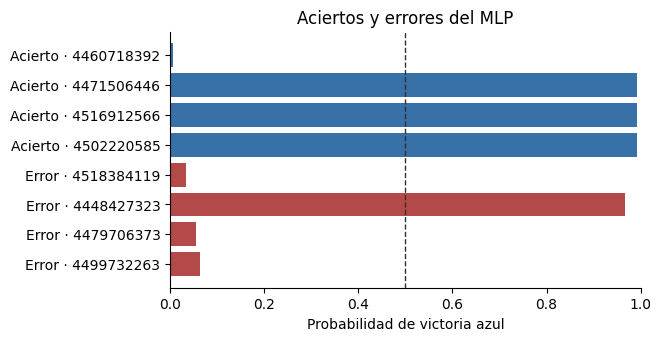

In [11]:
ejemplos = pd.DataFrame({
    "Partida": datos.iloc[indices_prueba]["gameId"].to_numpy(),
    "Oro azul menos rojo": variables.iloc[indices_prueba]["oro"].to_numpy(),
    "Ganador real": np.take(nombres_clases, y_prueba),
    "Ganador predicho": np.take(nombres_clases, pred_prueba_mlp),
    "Probabilidad de victoria azul": prob_prueba_mlp,
    "Acierto": y_prueba == pred_prueba_mlp,
})
ejemplos["Distancia al umbral"] = (ejemplos["Probabilidad de victoria azul"] - 0.50).abs()
ejemplos = ejemplos.sort_values("Distancia al umbral", ascending=False)
muestra = pd.concat([ejemplos[ejemplos["Acierto"]].head(4), ejemplos[~ejemplos["Acierto"]].head(4)])
display(muestra.drop(columns="Distancia al umbral").round(3).reset_index(drop=True))
assert set(muestra["Acierto"]) == {True, False}

fig, ax = plt.subplots(figsize=(6.5, 3.3), layout="constrained")
posiciones = np.arange(len(muestra))
etiquetas_ejemplos = [f"{'Acierto' if acierto else 'Error'} · {partida}"
                       for acierto, partida in zip(muestra["Acierto"], muestra["Partida"])]
ax.barh(posiciones, muestra["Probabilidad de victoria azul"],
        color=np.where(muestra["Acierto"], "#3771a8", "#b44949"))
ax.axvline(0.50, color="#303030", linestyle="--", linewidth=1)
ax.set(yticks=posiciones, yticklabels=etiquetas_ejemplos, xlim=(0, 1),
       xlabel="Probabilidad de victoria azul", title="Aciertos y errores del MLP")
ax.invert_yaxis()
plt.show()

## 7. Análisis y conclusiones

**Selección.** Elegí el MLP de una hidden layer en el epoch 47. Obtuvo un validation loss de 0.5245, frente a 0.5251 del MLP de dos capas. El modelo de dos capas sí obtuvo mayor validation accuracy (74.22 % frente a 73.75 %). Usé el loss como criterio porque quería comparar las probabilidades antes de convertirlas en clases.

**Comparación.** En las 1,482 partidas de test, el MLP obtuvo 71.26 % de accuracy y 0.7125 de macro F1-score. Logistic regression obtuvo 71.93 % y 0.7193. Con estas features, me quedaría con el baseline. La diferencia de 0.67 puntos porcentuales corresponde a este split.

**Caso de error.** En la partida 4518384119 el azul iba 4,552 de oro abajo al minuto 10. El MLP le dio 3.3 % de probabilidad de ganar y el azul terminó ganando. Con una sola medición por partida no pude estudiar cómo cambió esa ventaja.

**Siguiente prueba.** Buscaría partidas de otros rangos con fecha y parche para armar un split cronológico. Así podría evaluar si el modelo mantiene su rendimiento después de un cambio de parche.